# 10 - Try the frozen model on any coordinates

Exploration only. The frozen system (segformer_b2_t3, 3-seed ensemble, T = 1.733) is used as it is;
nothing here changes the model or the M5 test results.

Per location: 14 monthly Sentinel-1 composites (start-1 ... start+12), 12 monthly LULC maps,
% area per class per month, month-to-month and first-to-last change in percentage points,
reliability flags from the M5 pseudo-change thresholds, agreement with ESA WorldCover 2021 (label source, not
independent) and a monthly comparison with Google Dynamic World (independent, Sentinel-2 based).

**Runs on Colab or Kaggle** (detected automatically).
- **Colab:** upload `segformer_b2_t3_weights.zip`, `app_config.json` and `index_v2.csv` to `MyDrive/lulc_s1_global/`.
- **Kaggle:** turn Internet ON; attach the weights dataset (folders `segformer_b2_t3_s4X/best.pth`) and a dataset
  containing `app_config.json` and `index_v2.csv`. Results go to `/kaggle/working/try_coordinates`.

GPU is optional (about 2x faster); CPU works.

In [27]:
# 1. Setup
!pip install -q segmentation-models-pytorch earthengine-api pyproj
import os, json, zipfile, glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, segmentation_models_pytorch as smp
import ee
from matplotlib.colors import ListedColormap
from pyproj import Transformer

IN_KAGGLE = os.path.exists("/kaggle/input")
if IN_KAGGLE:
    IN, OUT = "/kaggle/input", "/kaggle/working"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    IN = OUT = "/content/drive/MyDrive/lulc_s1_global"

PROJECT_ID = "deep-learning-27"
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    # Kaggle: prints a link -> sign in with your Google account -> paste the code into the box.
    # The token stays inside this session only. Never print it, share it or commit it.
    ee.Authenticate(auth_mode="notebook" if IN_KAGGLE else None, force=True)
    ee.Initialize(project=PROJECT_ID)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("env:", "Kaggle" if IN_KAGGLE else "Colab", "| device:", DEV,
      "| torch", torch.__version__, "| smp", smp.__version__, "| ee", ee.__version__)

env: Kaggle | device: cpu | torch 2.11.0+cpu | smp 0.6.0 | ee 1.7.39


In [28]:
# 2. YOUR INPUT - edit this cell only
LOCATIONS = [            # (name, lat, lon)
    ("Lagos", 6.52,   3.38),   # cell 1_0: urban case study (screen recording city)
    ("Dallas", 32.78, -96.80),   # cell 6_-20: urban, near cloud-free Dynamic World all year
    ("La Palma eruption 2021", 28.615, -17.895), # cell 5_-4: real change, lava Sep-Dec 2021
]
START = "2021-01"        # first of the 12 output months (YYYY-MM). 2021 = same year/satellites as training
SIZE = 512               # map size in pixels at 10 m: 256 (2.56 km), 512 (5.12 km) or 768 (7.68 km)

In [29]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if root.count("/") <= 6:
        print(root, "|", [f for f in files if f.endswith((".pth", ".json", ".csv"))][:5])

/kaggle/input | []
/kaggle/input/datasets | []
/kaggle/input/datasets/rahuldevagiri | []
/kaggle/input/datasets/rahuldevagiri/lulc-app-config | ['app_config.json', 'index_v2.csv']
/kaggle/input/datasets/rahuldevagiri/lulc-m4-weights-segformer-b2-t3 | []
/kaggle/input/datasets/rahuldevagiri/lulc-m4-weights-segformer-b2-t3/segformer_b2_t3_s42 | ['best.pth']
/kaggle/input/datasets/rahuldevagiri/lulc-m4-weights-segformer-b2-t3/segformer_b2_t3_s43 | ['best.pth']
/kaggle/input/datasets/rahuldevagiri/lulc-m4-weights-segformer-b2-t3/segformer_b2_t3_s44 | ['best.pth']


In [30]:
# 3. Frozen configuration and the 3 models (CPU)
def find(pattern):
    """First file matching pattern anywhere under IN (Kaggle mounts datasets in nested folders)."""
    if os.path.exists(f"{IN}/{pattern}"):               # Colab: file directly in the Drive folder (fast)
        return f"{IN}/{pattern}"
    hits = sorted(glob.glob(f"{IN}/**/{pattern}", recursive=True))
    assert hits, f"{pattern} not found under {IN} - attach/upload it first"
    return hits[0]

CFG = json.load(open(find("app_config.json")))
PRE, CLASSES, COLORS = CFG["preprocessing"], CFG["classes"], CFG["colors"]
NC, TEMP, RES, TILE = len(CLASSES), CFG["model"]["temperature"], 10, 256
THR_M2M = CFG["change_thresholds_pp"]["month_to_month_p95"]
THR_FL = CFG["change_thresholds_pp"]["first_to_last_p95"]
AREA_ERR = CFG["area_error_pp"]["mean"]

if IN_KAGGLE:                          # weights dataset: segformer_b2_t3_s4X/best.pth (duplicates ignored)
    found = {}
    for w in sorted(glob.glob(f"{IN}/**/segformer_b2_t3_s*/best.pth", recursive=True)):
        found.setdefault(os.path.basename(os.path.dirname(w)), w)
    W = [found[k] for k in sorted(found)]
else:
    WDIR = "/content/weights"
    if not os.path.exists(WDIR):
        zipfile.ZipFile(f"{OUT}/segformer_b2_t3_weights.zip").extractall(WDIR)
    W = sorted(glob.glob(f"{WDIR}/segformer_b2_t3_s*/best.pth"))
assert len(W) == 3, W

def load(w):
    m = smp.Segformer("mit_b2", encoder_weights=None, in_channels=9, classes=NC)
    sd = torch.load(w, map_location="cpu", weights_only=False)
    if isinstance(sd, dict) and "model" in sd:
        sd = sd["model"]
    m.load_state_dict(sd)              # strict: fails loudly if the architecture differs
    return m.eval().to(DEV)

MODELS = [load(w) for w in W]
torch.set_num_threads(os.cpu_count())
print("loaded:", [os.path.basename(os.path.dirname(w)) for w in W], "| T =", TEMP, "| device:", DEV)

# training-split lookup (which split was this 5-degree cell in?)
idx = pd.read_csv(find("index_v2.csv"), usecols=["lat", "lon", "split"])
idx["cell"] = (idx.lat // 5).astype(int).astype(str) + "_" + (idx.lon // 5).astype(int).astype(str)
CELL_SPLIT = idx.groupby("cell").split.agg(lambda s: "/".join(sorted(set(s)))).to_dict()

loaded: ['segformer_b2_t3_s42', 'segformer_b2_t3_s43', 'segformer_b2_t3_s44'] | T = 1.733 | device: cpu


In [32]:
# 4. Sentinel-1 fetch: IDENTICAL to training (notebooks 01 / 04)
NODATA = PRE["nodata"]

def s1_collection(region, start, end):
    def mask_edges(img):
        a = img.select("angle")
        return img.updateMask(a.gt(30.6).And(a.lt(45.2)))
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .map(mask_edges).select(["VV", "VH"]))

def monthly_composite(region, start, i):
    s = ee.Date(start).advance(i, "month")
    col = s1_collection(region, s, s.advance(1, "month"))
    empty = ee.Image.constant([0, 0]).rename(["VV", "VH"]).updateMask(0)
    img = ee.Image(ee.Algorithms.If(col.size().gt(0), col.median(), empty))
    return img.multiply(100).round().unmask(NODATA).toInt16().rename([f"VV_{i:02d}", f"VH_{i:02d}"])

def utm_epsg(lat, lon):
    z = int((lon + 180) / 6) + 1
    return f"EPSG:{32600 + z if lat >= 0 else 32700 + z}"

FROM = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
TO = [0, 1, 1, 2, 3, 4, 255, 5, 6, 0, 1]

# Google Dynamic World V1 (Sentinel-2 based, NOT used for training) -> our 7 classes. snow_and_ice -> 255.
# DW: 0 water, 1 trees, 2 grass, 3 flooded_vegetation, 4 crops, 5 shrub_and_scrub, 6 built, 7 bare, 8 snow_and_ice
DW_FROM = [0, 1, 2, 3, 4, 5, 6, 7, 8]
DW_TO = [5, 0, 1, 6, 2, 1, 3, 4, 255]

def dw_monthly(region, start, i):
    """Per-pixel mode of the Dynamic World label in month i (cloud-free S2 scenes only); 255 = no DW data."""
    s = ee.Date(start).advance(i, "month")
    col = (ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterBounds(region)
           .filterDate(s, s.advance(1, "month")).select("label"))
    empty = ee.Image.constant(0).rename("label").updateMask(0)
    img = ee.Image(ee.Algorithms.If(col.size().gt(0), col.reduce(ee.Reducer.mode()).rename("label"), empty))
    return img.remap(DW_FROM, DW_TO, 255).unmask(255).toInt16().rename(f"DW_{i:02d}")

def validate(lat, lon, start, size):
    if not (-90 <= lat <= 90 and -180 <= lon <= 180):
        raise ValueError(f"lat/lon out of range: {lat}, {lon}")
    if size not in (256, 512, 768):
        raise ValueError("SIZE must be 256, 512 or 768")
    first = pd.Timestamp(start + "-01") - pd.DateOffset(months=1)          # m-1 of the first month
    last = pd.Timestamp(start + "-01") + pd.DateOffset(months=13)          # end of m+1 of the 12th month
    if first < pd.Timestamp("2014-10-01"):
        raise ValueError("Sentinel-1 IW data start in Oct 2014: choose START >= 2014-11")
    if last > pd.Timestamp.today().normalize().replace(day=1):
        raise ValueError(f"START too late: needs complete data through {last - pd.DateOffset(months=1):%Y-%m}")

def fetch(lat, lon, start, size):
    """-> s1 (14, 2, H, W) int16 dB*100 for months start-1 ... start+12, label (H, W), images per month,
    dw (12, H, W) Dynamic World monthly mode for the 12 output months (255 = no data)."""
    s0 = (pd.Timestamp(start + "-01") - pd.DateOffset(months=1)).strftime("%Y-%m-%d")
    crs = utm_epsg(lat, lon)
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(lon, lat)
    x0, y0 = round(x / RES) * RES - size * RES // 2, round(y / RES) * RES + size * RES // 2
    region = ee.Geometry.Point([lon, lat]).buffer(size * RES * 0.8).bounds()
    label = (ee.ImageCollection("ESA/WorldCover/v200").first()
             .remap(FROM, TO, 255).unmask(255).toInt16().rename("label"))
    stack = ee.Image.cat([monthly_composite(region, s0, i) for i in range(14)] + [label])
    grid = {"dimensions": {"width": size, "height": size}, "crsCode": crs,
            "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                "shearY": 0, "scaleY": -RES, "translateY": y0}}
    arr = ee.data.computePixels({"expression": stack, "fileFormat": "NUMPY_NDARRAY", "grid": grid})
    # Dynamic World in a separate request on the SAME grid (keeps each request under the size limit)
    dw_stack = ee.Image.cat([dw_monthly(region, s0, i) for i in range(1, 13)]).toUint8()
    arr_dw = ee.data.computePixels({"expression": dw_stack, "fileFormat": "NUMPY_NDARRAY", "grid": grid})
    s1 = np.stack([arr[f"{b}_{i:02d}"] for i in range(14) for b in ("VV", "VH")]).reshape(14, 2, size, size)
    s = ee.Date(s0)
    counts = ee.List.sequence(0, 13).map(lambda i: s1_collection(
        region, s.advance(i, "month"), s.advance(ee.Number(i).add(1), "month")).size()).getInfo()
    dw = np.stack([arr_dw[f"DW_{i:02d}"] for i in range(1, 13)]).astype(np.uint8)
    return s1, arr["label"].astype(np.uint8), counts, dw

In [34]:
# 5. Preprocess + ensemble prediction: IDENTICAL preprocessing to training (notebook 06, K2.1)
def preprocess(x2):
    nod = (x2[0] == NODATA) | (x2[1] == NODATA)
    vv = np.clip(x2[0] / PRE["scale"], *PRE["clip"]["VV"])
    vh = np.clip(x2[1] / PRE["scale"], *PRE["clip"]["VH"])
    img = np.stack([vv, vh, vv - vh]).astype(np.float32)
    img = (img - np.array(PRE["mean"], np.float32)[:, None, None]) / np.array(PRE["std"], np.float32)[:, None, None]
    img[:, nod] = 0.0
    return img, nod

def ensemble_probs(x9, stride=TILE // 2, batch=8):
    """x9: (9, H, W) -> calibrated probabilities (NC, H, W).
    Overlapping 256-px windows (stride 128), blended with a tapered weight to remove tile seams.
    Temperature is applied AFTER blending the ensemble-mean probabilities.
    For H = W = 256 this is exactly one window = identical to the M5 test setting."""
    H, Wd = x9.shape[1:]
    starts = lambda n: sorted(set(list(range(0, n - TILE + 1, stride)) + [n - TILE]))
    tiles = [(r, c) for r in starts(H) for c in starts(Wd)]
    h = 0.1 + 0.9 * np.sin(np.pi * (np.arange(TILE) + 0.5) / TILE)     # >0 everywhere, peak in centre
    w = np.outer(h, h).astype(np.float32)
    acc = np.zeros((NC, H, Wd), np.float32); wsum = np.zeros((H, Wd), np.float32)
    with torch.no_grad():
        for i in range(0, len(tiles), batch):
            part = tiles[i:i + batch]
            xb = torch.from_numpy(np.stack([x9[:, r:r + TILE, c:c + TILE] for r, c in part])).to(DEV)
            pbar = (sum(m(xb).softmax(1) for m in MODELS) / len(MODELS)).cpu().numpy()
            for k, (r, c) in enumerate(part):
                acc[:, r:r + TILE, c:c + TILE] += pbar[k] * w
                wsum[r:r + TILE, c:c + TILE] += w
    pbar = acc / wsum
    return torch.softmax(torch.log(torch.from_numpy(pbar).clamp_min(1e-8)) / TEMP, 0).numpy()

def predict_12(s1):
    """s1: (14, 2, H, W) -> pred (12, H, W) uint8 (255 = nodata), conf (12, H, W), list of substituted neighbours.
    A neighbour month with NO data at all is replaced by the centre month, exactly as in training."""
    pre = [preprocess(s1[i]) for i in range(14)]
    empty = [bool(p[1].all()) for p in pre]                   # whole month without any S1 pixel
    preds, confs, subst = [], [], []
    for m in range(1, 13):                                    # output month m uses m-1, m, m+1
        prev = pre[m][0] if empty[m - 1] else pre[m - 1][0]
        nxt = pre[m][0] if empty[m + 1] else pre[m + 1][0]
        if empty[m - 1] or empty[m + 1]:
            subst.append(m - 1)                               # 0-based output month index
        p = ensemble_probs(np.concatenate([prev, pre[m][0], nxt]))
        pred, conf = p.argmax(0).astype(np.uint8), p.max(0)
        nod = pre[m][1]                                       # centre-month gaps -> nodata (as in training)
        pred[nod], conf[nod] = 255, np.nan
        preds.append(pred); confs.append(conf)
    return np.stack(preds), np.stack(confs), subst

In [35]:
# 6. Statistics: P(c,m) = 100 * A(c,m) / A(valid,m); dP in percentage points; flags from M5 thresholds
# Low-reliability month: mean calibrated confidence < CONF_MIN. Heuristic chosen from the demo locations
# (not validated on the test set). Change flags involving such a month are not trusted.
CONF_MIN = 0.65

def stats_tables(pred, conf, lab, months):
    rows = []
    for m, mo in enumerate(months):
        v = pred[m] != 255
        nv = int(v.sum())
        mc = round(float(np.nanmean(conf[m])), 3) if nv else np.nan
        row = {"month": mo, "valid_%": round(100 * nv / v.size, 1), "mean_conf": mc,
               "reliable": "yes" if nv and mc >= CONF_MIN else "LOW"}
        cnt = np.bincount(pred[m][v], minlength=NC)
        for c, name in enumerate(CLASSES):
            row[name] = round(100 * cnt[c] / nv, 2) if nv else np.nan
        both = v & (lab != 255)                              # agreement with WorldCover 2021
        row["agree_WC_%"] = round(100 * float((pred[m][both] == lab[both]).mean()), 1) if both.any() else np.nan
        rows.append(row)
    P = pd.DataFrame(rows).set_index("month")

    dP = P[CLASSES].diff().iloc[1:].round(2)                 # month-to-month, percentage points
    big = dP.abs().gt(pd.Series(THR_M2M))
    rel = P["reliable"].eq("yes")
    pair_ok = (rel & rel.shift(1, fill_value=False)).iloc[1:]  # both months of the pair reliable
    flags = pd.DataFrame("", index=dP.index, columns=CLASSES)
    flags[big & pair_ok.values[:, None]] = "CHANGE?"
    flags[big & ~pair_ok.values[:, None]] = "(low conf)"
    ok = P[P[CLASSES].notna().all(axis=1)]
    fl = pd.DataFrame()
    if len(ok) >= 2:
        fl = pd.DataFrame({"first_%": ok[CLASSES].iloc[0], "last_%": ok[CLASSES].iloc[-1]})
        fl["dP_pp"] = (fl["last_%"] - fl["first_%"]).round(2)
        fl["threshold_pp"] = pd.Series(THR_FL)
        ends_ok = ok["reliable"].iloc[0] == "yes" and ok["reliable"].iloc[-1] == "yes"
        fl["reliable_change"] = np.where(fl.dP_pp.abs() <= fl.threshold_pp, "no (within seasonal/noise range)",
                                         "yes" if ends_ok else "unknown (first or last month low confidence)")
        k = min(3, len(ok) // 2)                             # descriptive: mean of first k vs last k valid months
        fl[f"dP_{k}mo_mean_pp"] = (ok[CLASSES].iloc[-k:].mean() - ok[CLASSES].iloc[:k].mean()).round(2)
        fl["typical_area_error_pp"] = pd.Series(AREA_ERR)
    v = lab != 255
    wc = pd.Series([round(100 * float((lab[v] == c).mean()), 2) if v.any() else np.nan for c in range(NC)],
                   index=CLASSES, name="WorldCover2021_%")
    return P, dP, flags, fl, wc

def dw_tables(pred, dw, months):
    """Independent check against Google Dynamic World (Sentinel-2, not used for training).
    Per month: DW coverage, agreement, DW class shares, and the model's shares on the SAME pixels.
    Pooled over 12 months: per-class IoU / F1 of the model vs DW."""
    rows, cm = [], np.zeros((NC, NC), np.int64)
    for m, mo in enumerate(months):
        both = (pred[m] != 255) & (dw[m] != 255)
        row = {"month": mo, "DW_valid_%": round(100 * float((dw[m] != 255).mean()), 1)}
        if both.sum() >= 100:
            p, d = pred[m][both], dw[m][both]
            row["agree_DW_%"] = round(100 * float((p == d).mean()), 1)
            cp, cd = np.bincount(p, minlength=NC), np.bincount(d, minlength=NC)
            for c, name in enumerate(CLASSES):
                row[f"{name} model/DW"] = f"{100 * cp[c] / both.sum():.1f}/{100 * cd[c] / both.sum():.1f}"
            cm += np.bincount(d.astype(np.int64) * NC + p, minlength=NC * NC).reshape(NC, NC)  # rows = DW
        else:
            row["agree_DW_%"] = np.nan                       # too few cloud-free DW pixels this month
        rows.append(row)
    T = pd.DataFrame(rows).set_index("month")
    tp = np.diag(cm).astype(float); den_iou = cm.sum(0) + cm.sum(1) - tp; den_f1 = cm.sum(0) + cm.sum(1)
    pc = pd.DataFrame({"IoU_vs_DW": np.where(den_iou > 0, tp / np.maximum(den_iou, 1), np.nan).round(3),
                       "F1_vs_DW": np.where(den_f1 > 0, 2 * tp / np.maximum(den_f1, 1), np.nan).round(3),
                       "DW_pixel_share_%": (100 * cm.sum(1) / max(cm.sum(), 1)).round(2)}, index=CLASSES)
    oa = float(tp.sum() / cm.sum()) if cm.sum() else np.nan
    return T, pc, oa

In [36]:
# 7. Plots
CMAP = ListedColormap(COLORS)

def plot_location(name, pred, conf, lab, P, months):
    fig, ax = plt.subplots(3, 5, figsize=(20, 12.5))
    for m in range(12):
        a = ax.ravel()[m]
        a.imshow(np.ma.masked_equal(pred[m], 255), cmap=CMAP, vmin=0, vmax=NC - 1, interpolation="nearest")
        low = " | LOW CONF" if P["reliable"].iloc[m] != "yes" else ""
        a.set_title(f"{months[m]} | valid {P['valid_%'].iloc[m]}%{low}", color="red" if low else "black"); a.axis("off")
    a = ax.ravel()[12]
    a.imshow(np.ma.masked_equal(lab, 255), cmap=CMAP, vmin=0, vmax=NC - 1, interpolation="nearest")
    a.set_title("ESA WorldCover 2021 (reference)"); a.axis("off")
    a = ax.ravel()[13]
    im = a.imshow(np.nanmean(conf, 0), cmap="viridis", vmin=0.3, vmax=1)
    a.set_title("mean calibrated confidence"); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046)
    a = ax.ravel()[14]; a.axis("off")
    a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="center", fontsize=12)
    fig.suptitle(name, fontsize=16); plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 4.5))
    for c, col in zip(CLASSES, COLORS):
        ax.plot(range(12), P[c].values, "o-", color=col, label=c)
    ax.set_xticks(range(12)); ax.set_xticklabels(months, rotation=45)
    ax.set_ylabel("% of valid area"); ax.set_title(f"{name}: class shares per month"); ax.grid(alpha=.3)
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

def plot_dw(name, dw, T, months):
    """Dynamic World monthly reference maps (white = clouds / no DW data / snow-ice)."""
    fig, ax = plt.subplots(3, 5, figsize=(20, 12.5))
    for m in range(12):
        a = ax.ravel()[m]
        a.imshow(np.ma.masked_equal(dw[m], 255), cmap=CMAP, vmin=0, vmax=NC - 1, interpolation="nearest")
        a.set_title(f"DW {months[m]} | cover {T['DW_valid_%'].iloc[m]}% | agree {T['agree_DW_%'].iloc[m]}%")
        a.axis("off")
    for a in ax.ravel()[12:]: a.axis("off")
    ax.ravel()[13].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES,
                          loc="center", fontsize=12)
    fig.suptitle(f"{name}: Google Dynamic World (independent, Sentinel-2 based)", fontsize=16)
    plt.tight_layout(); plt.show()

Lagos (6.52, 3.38) | 5.12 km square | 5-degree cell 1_0: test
  S1 images per month: {'2020-12': 5, '2021-01': 4, '2021-02': 5, '2021-03': 5, '2021-04': 5, '2021-05': 5, '2021-06': 6, '2021-07': 5, '2021-08': 5, '2021-09': 5, '2021-10': 5, '2021-11': 4, '2021-12': 5, '2022-01': 5}
  done in 70 s

% of valid area per class (+ valid share, mean confidence, agreement with WorldCover 2021):
         valid_%  mean_conf reliable  Tree  Shrub/Grass  Cropland  Built-up  Bare  Water  Wetland  agree_WC_%
month                                                                                                        
2021-01    100.0      0.839      yes  6.31         1.30      0.10     85.46  0.26   6.48     0.08        94.5
2021-02    100.0      0.838      yes  6.06         1.31      0.20     85.57  0.33   6.46     0.05        94.5
2021-03    100.0      0.840      yes  5.97         1.20      0.01     86.01  0.20   6.56     0.05        94.7
2021-04    100.0      0.841      yes  6.21         1.16     

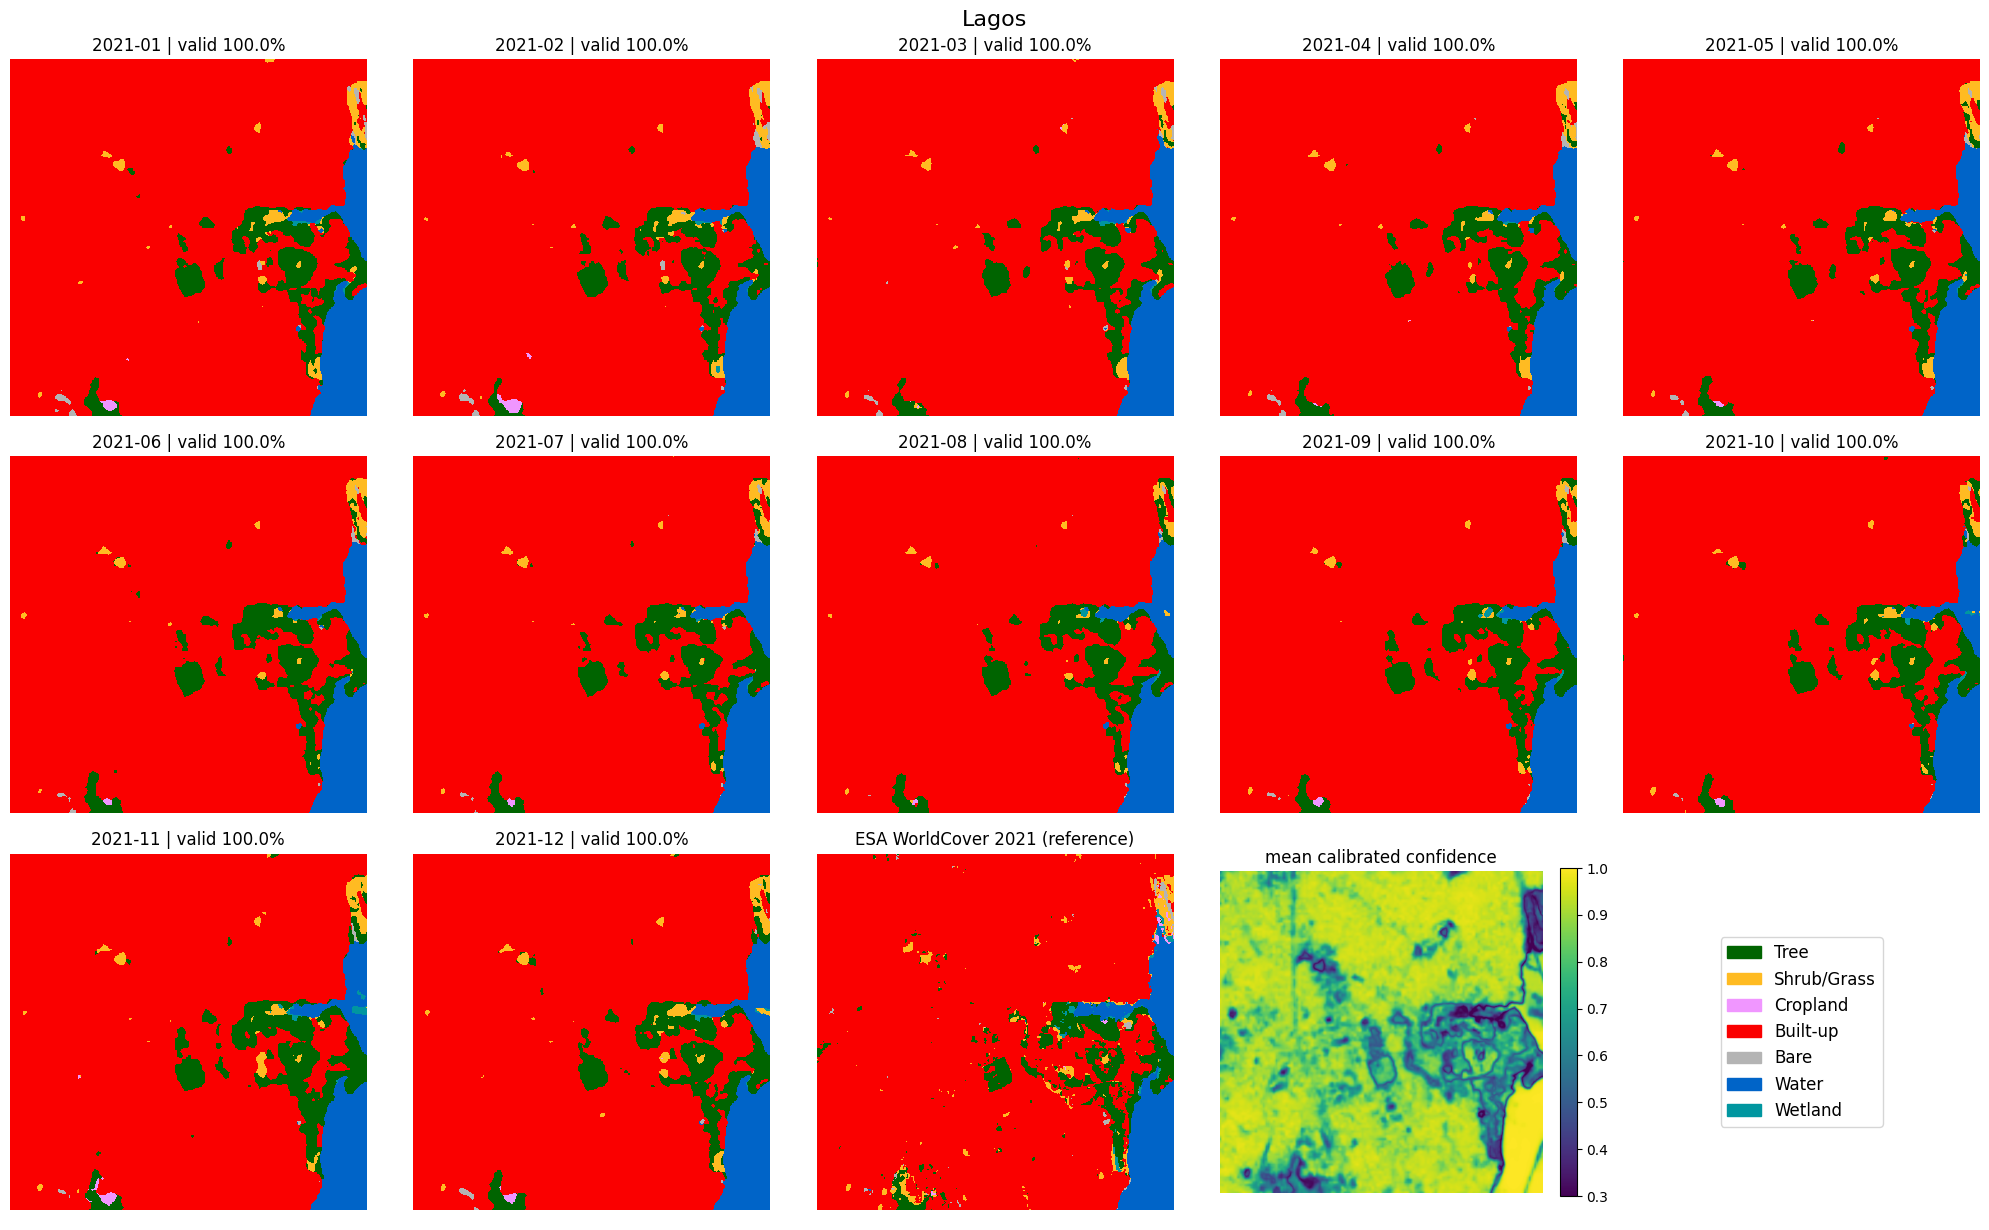

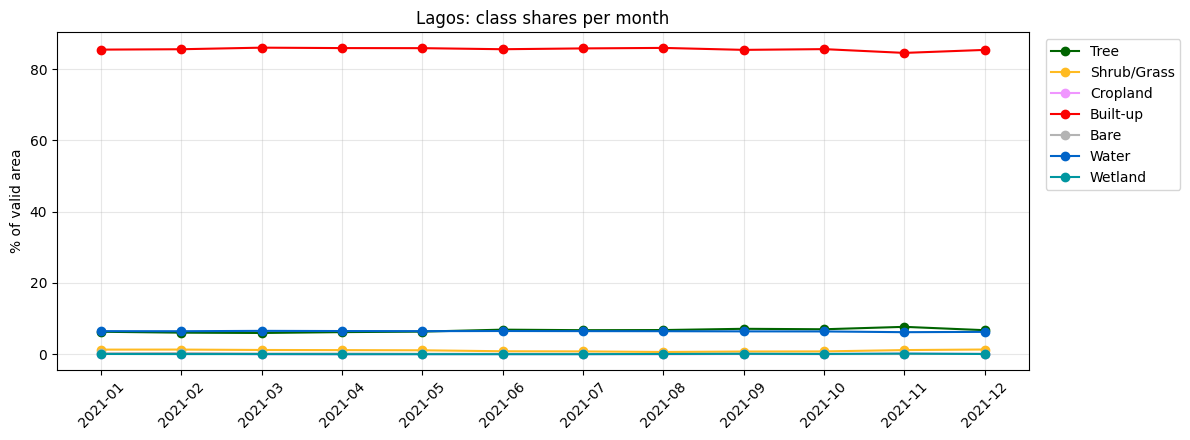

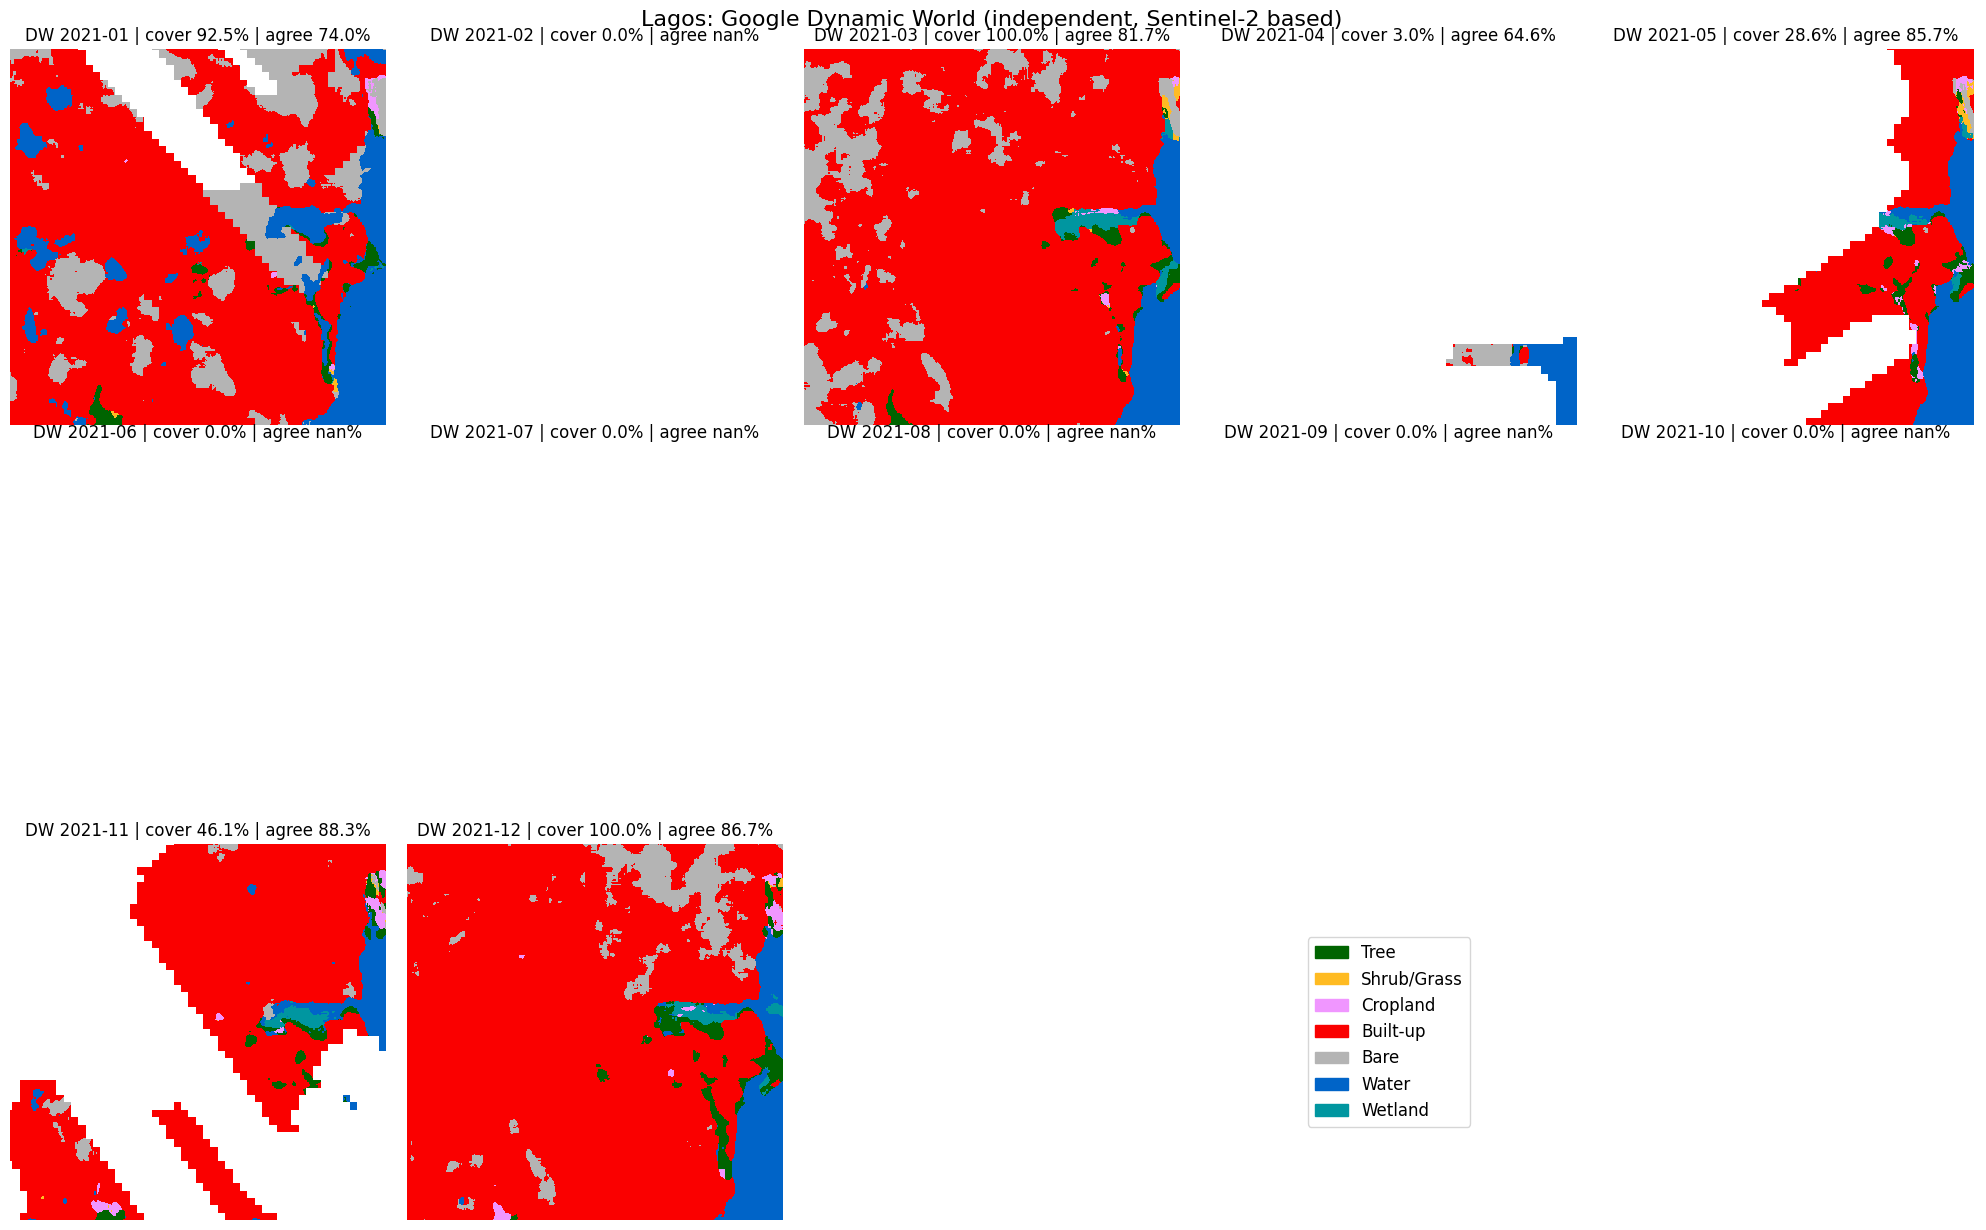

Dallas (32.78, -96.8) | 5.12 km square | 5-degree cell 6_-20: test
  S1 images per month: {'2020-12': 4, '2021-01': 6, '2021-02': 4, '2021-03': 6, '2021-04': 4, '2021-05': 6, '2021-06': 4, '2021-07': 6, '2021-08': 4, '2021-09': 6, '2021-10': 6, '2021-11': 2, '2021-12': 6, '2022-01': 4}
  done in 75 s
  NOTE: fewer than 3 S1 images in ['2021-11'] -> noisier monthly composite.

% of valid area per class (+ valid share, mean confidence, agreement with WorldCover 2021):
         valid_%  mean_conf reliable  Tree  Shrub/Grass  Cropland  Built-up  Bare  Water  Wetland  agree_WC_%
month                                                                                                        
2021-01    100.0      0.682      yes  3.67         1.13      9.48     85.02  0.28   0.42      0.0        72.8
2021-02    100.0      0.689      yes  3.99         1.05      9.45     84.85  0.27   0.39      0.0        72.9
2021-03    100.0      0.682      yes  4.45         0.91      9.74     84.19  0.28   0.43 

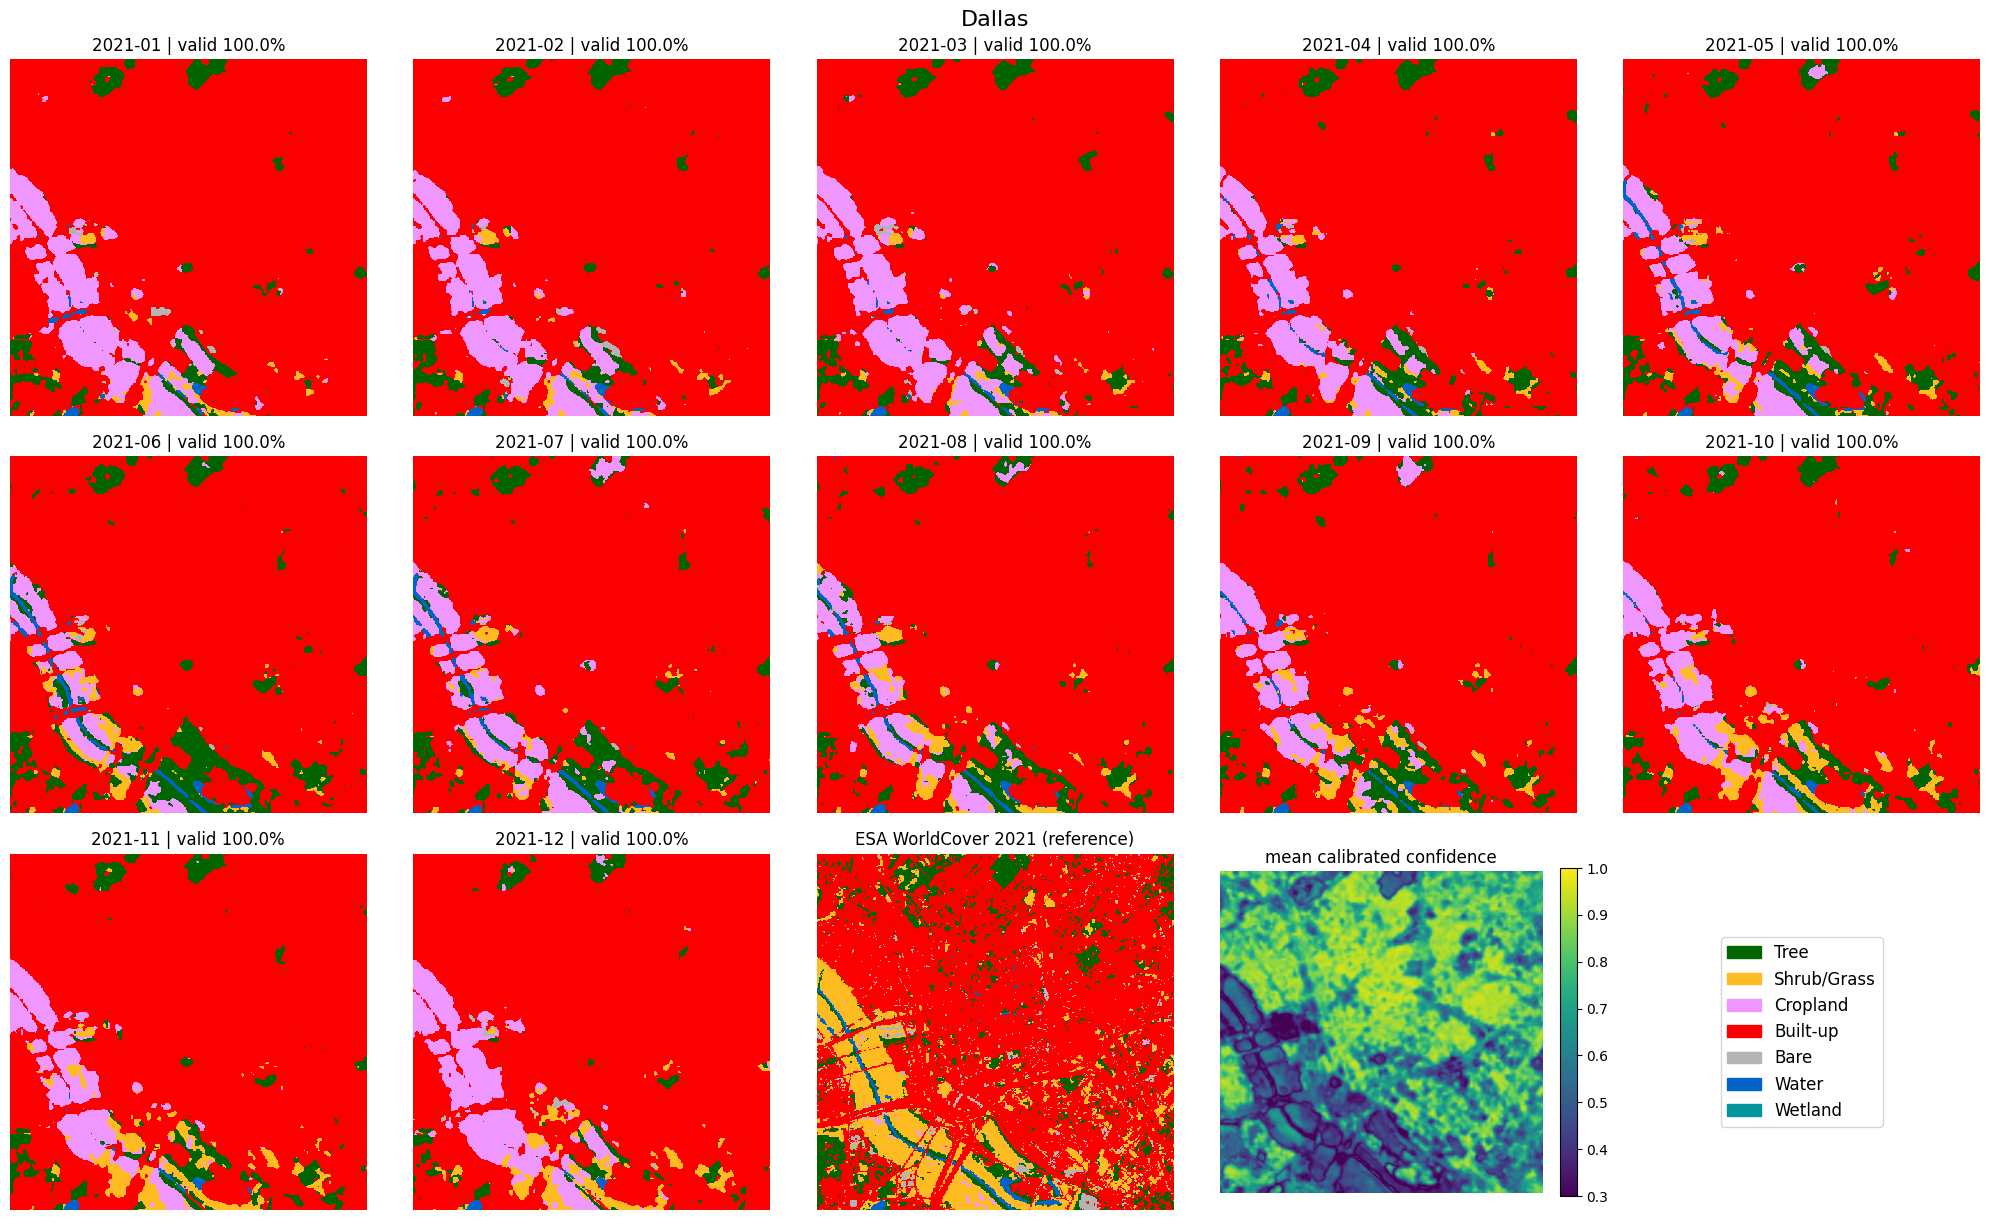

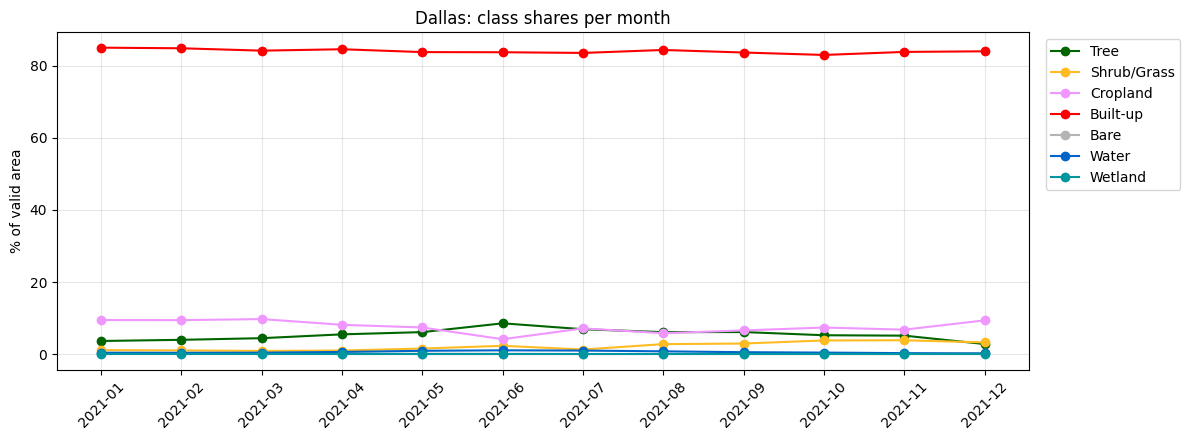

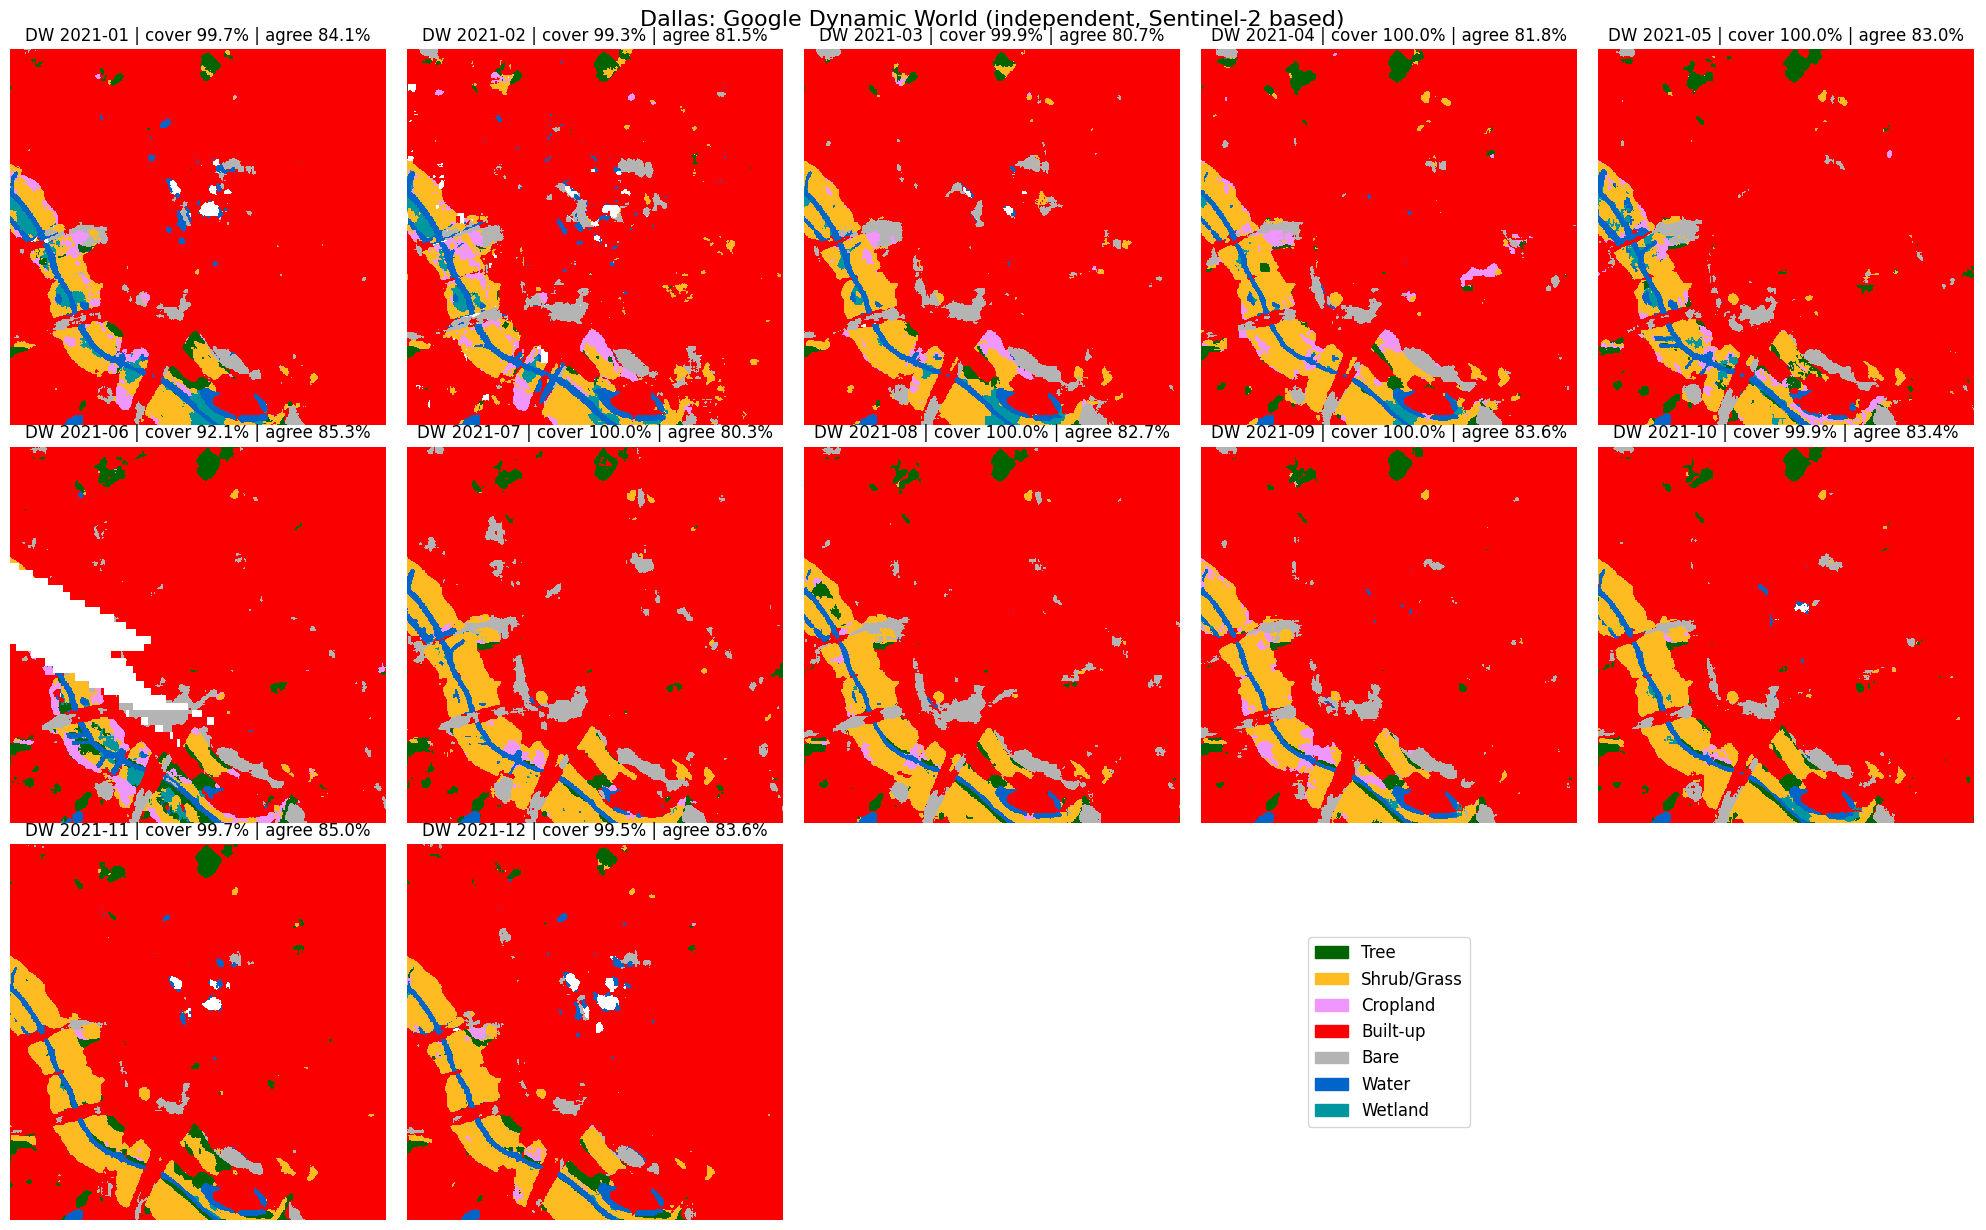

La Palma eruption 2021 (28.615, -17.895) | 5.12 km square | 5-degree cell 5_-4: test
  S1 images per month: {'2020-12': 10, '2021-01': 11, '2021-02': 8, '2021-03': 8, '2021-04': 10, '2021-05': 11, '2021-06': 10, '2021-07': 10, '2021-08': 9, '2021-09': 9, '2021-10': 8, '2021-11': 10, '2021-12': 10, '2022-01': 4}
  done in 70 s

% of valid area per class (+ valid share, mean confidence, agreement with WorldCover 2021):
         valid_%  mean_conf reliable   Tree  Shrub/Grass  Cropland  Built-up   Bare  Water  Wetland  agree_WC_%
month                                                                                                          
2021-01    100.0      0.536      LOW  26.36        33.56      9.61     30.11   0.22   0.14     0.00        45.8
2021-02    100.0      0.549      LOW  28.40        36.15      8.03     26.94   0.34   0.14     0.00        49.0
2021-03    100.0      0.559      LOW  26.56        29.72      9.69     33.42   0.46   0.15     0.00        43.5
2021-04    100.0   

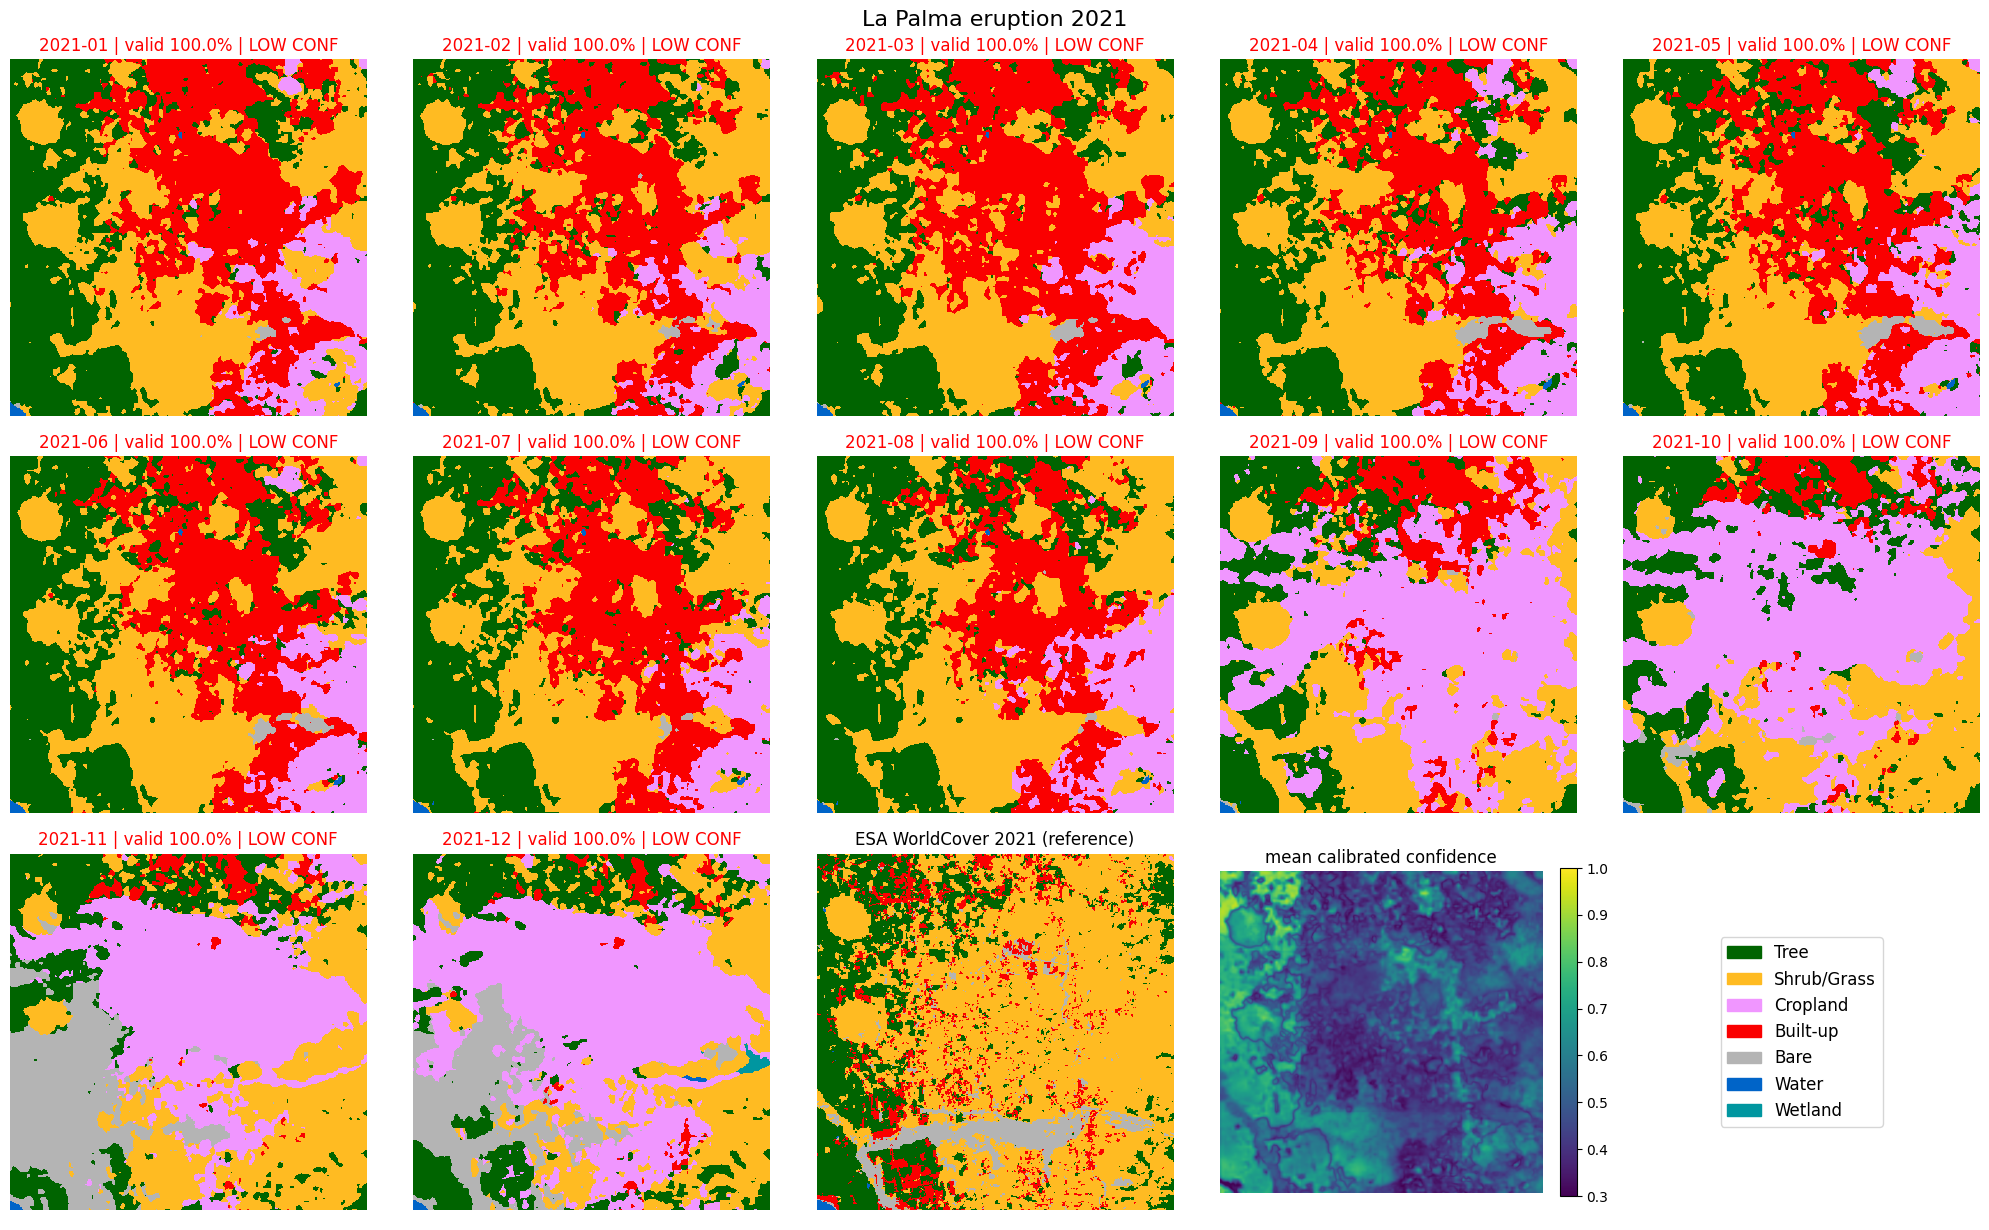

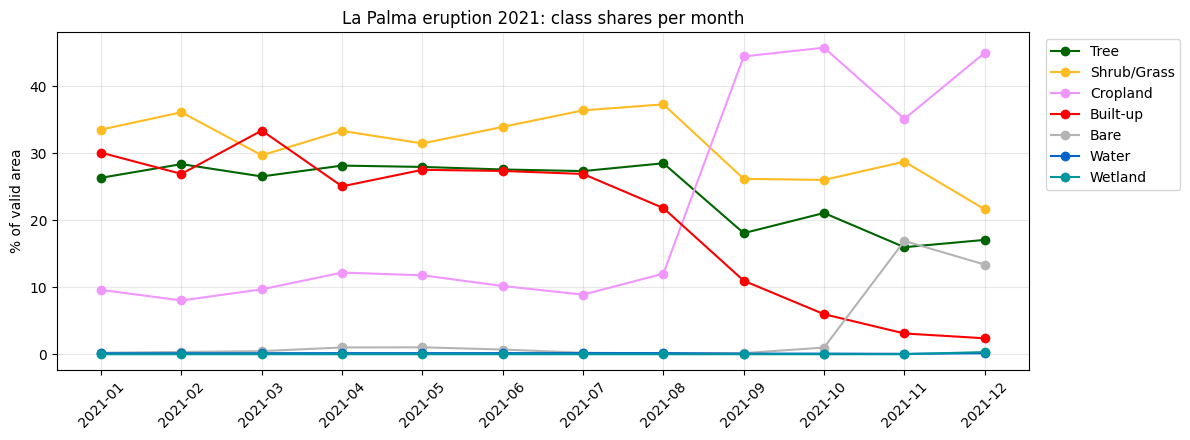

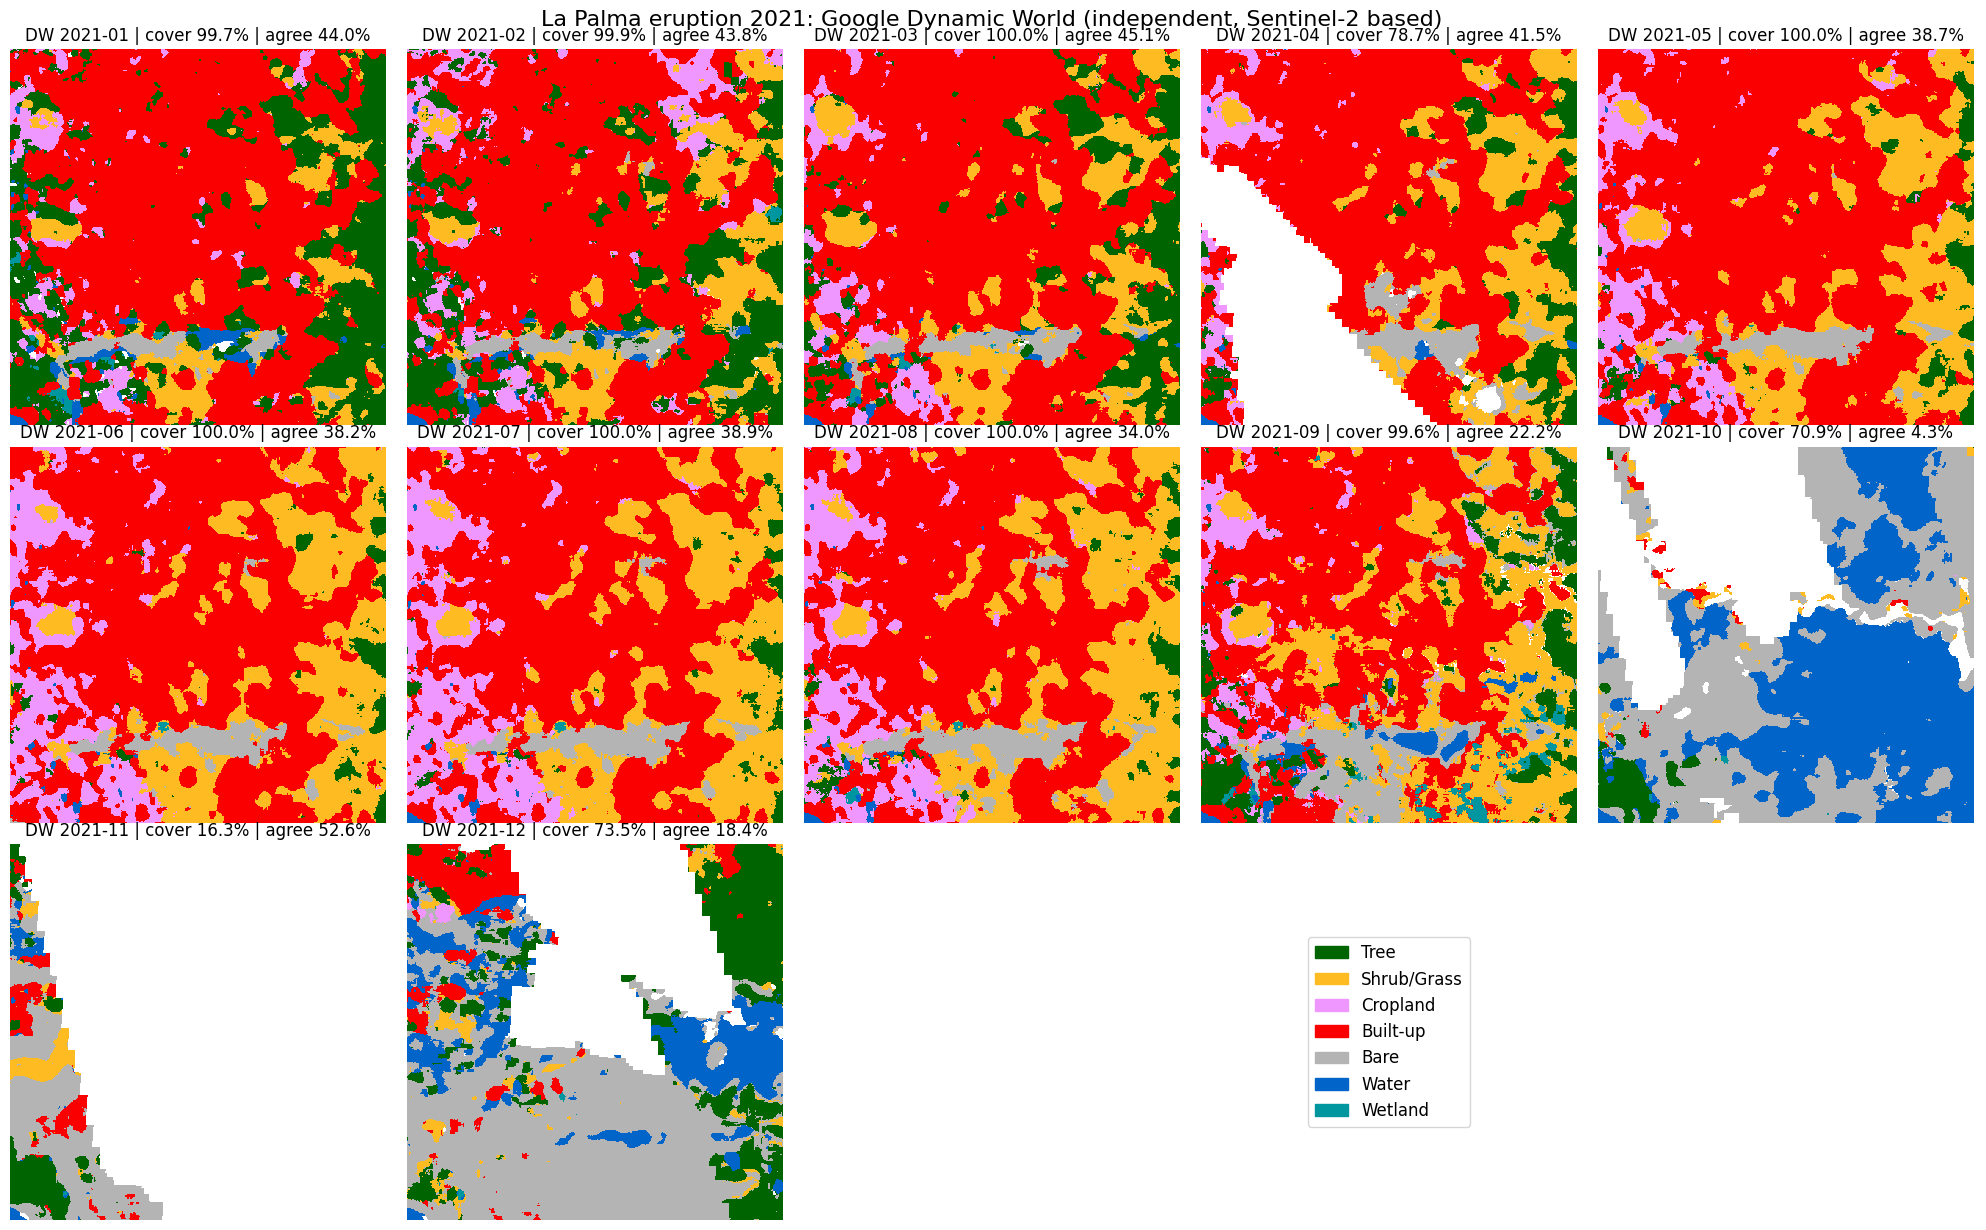


saved to /kaggle/working/try_coordinates


In [37]:
# 8. Run
months = pd.date_range(START + "-01", periods=12, freq="MS").strftime("%Y-%m").tolist()
RES_DIR = f"{OUT}/try_coordinates"; os.makedirs(RES_DIR, exist_ok=True)
for name, lat, lon in LOCATIONS:
    print("=" * 100)
    try:
        validate(lat, lon, START, SIZE)
    except ValueError as e:
        print(f"{name}: INVALID INPUT - {e}"); continue
    cell = f"{int(lat // 5)}_{int(lon // 5)}"
    split = CELL_SPLIT.get(cell, "no samples (unknown)")
    print(f"{name} ({lat}, {lon}) | {SIZE * RES / 1000:.2f} km square | 5-degree cell {cell}: {split}")
    if "train" in split or "val" in split:
        print("  NOTE: this region was used for training/validation -> agreement is optimistic.")
    t0 = time.time()
    s1, lab, counts, dw = fetch(lat, lon, START, SIZE)
    all_months = pd.date_range(START + "-01", periods=14, freq="MS") - pd.DateOffset(months=1)
    print("  S1 images per month:", dict(zip(all_months.strftime("%Y-%m"), counts)))
    if sum(counts[1:13]) == 0:
        print("  NO Sentinel-1 data at this location/period (or all removed by the swath-edge mask). No maps."); continue
    pred, conf, subst = predict_12(s1)
    P, dP, flags, fl, wc = stats_tables(pred, conf, lab, months)
    print(f"  done in {time.time() - t0:.0f} s")
    if subst:
        print("  NOTE: neighbour month without data -> centre month repeated (as in training) for:",
              [months[i] for i in subst])
    few = [m for m, n in zip(all_months.strftime("%Y-%m"), counts) if 0 < n < 3]
    if few:
        print("  NOTE: fewer than 3 S1 images in", few, "-> noisier monthly composite.")
    low = P[P["valid_%"] < 50].index.tolist()
    if low:
        print("  WARNING: < 50% valid pixels in", low, "-> percentages there are unreliable.")
    lowc = P[P["reliable"] != "yes"].index.tolist()
    if lowc:
        print(f"  WARNING: mean confidence < {CONF_MIN} in", lowc, "-> maps and changes there are not trusted.")
    s1_ok = pred.min(0) != 255                                # pixels with S1 data in at least one month
    out_cls = 100 * float((lab[s1_ok] == 255).mean()) if s1_ok.any() else 0.0
    if out_cls > 20:
        print(f"  WARNING: {out_cls:.0f}% of the area is outside the 7 classes in WorldCover (e.g. snow/ice) or unmapped."
              " The model must still pick one of 7 classes there; agree_WC_% covers only the rest.")
    print("\n% of valid area per class (+ valid share, mean confidence, agreement with WorldCover 2021):")
    print(P.to_string())
    print("\nWorldCover 2021 shares (reference, %):"); print(wc.to_string())
    print("\nMonth-to-month change (pp); 'CHANGE?' = larger than the M5 95% pseudo-change level;"
          " '(low conf)' = large but a month of the pair is low confidence:")
    print(dP.astype(str).where(flags == "", dP.astype(str) + " " + flags).to_string())
    print("\nFirst-to-last change:"); print(fl.to_string())
    T, pc, oa_dw = dw_tables(pred, dw, months)
    print("\nINDEPENDENT CHECK - Google Dynamic World (Sentinel-2 based, not used for training).")
    print("Per month: DW coverage (clouds reduce it), agreement, and class % model/DW on the same pixels:")
    print(T.to_string())
    print(f"\nPooled over 12 months: overall agreement with DW = {100 * oa_dw:.1f}%; per class (rows = DW class):")
    print(pc.to_string())
    plot_location(name, pred, conf, lab, P, months)
    plot_dw(name, dw, T, months)
    safe = name.replace(" ", "_")
    P.to_csv(f"{RES_DIR}/{safe}_{START}_shares.csv"); dP.to_csv(f"{RES_DIR}/{safe}_{START}_dP.csv")
    fl.to_csv(f"{RES_DIR}/{safe}_{START}_first_last.csv")
    T.to_csv(f"{RES_DIR}/{safe}_{START}_dynamicworld_monthly.csv")
    pc.to_csv(f"{RES_DIR}/{safe}_{START}_dynamicworld_per_class.csv")
    np.savez_compressed(f"{RES_DIR}/{safe}_{START}_maps.npz", pred=pred, conf=conf.astype(np.float16),
                        label=lab, dw=dw, months=np.array(months))
print("\nsaved to", RES_DIR)

### How to read the output
- **Valid %**: share of pixels with Sentinel-1 data in that month (swath-edge mask, no acquisitions -> nodata).
- **Class %** use only valid pixels: P(c,m) = 100 * A(c,m) / A(valid,m).
- **agree_WC_%**: pixel agreement with WorldCover 2021. WorldCover 2021 is the SAME product the training labels came
  from, so it is not an independent check. It is not accuracy either: WorldCover is ~77% accurate, and for
  years other than 2021 real change also lowers it.
- **Dynamic World (independent check)**: Google Dynamic World V1 is a 10 m near-real-time LULC product derived from
  Sentinel-2 optical images; it was not used for training. Monthly reference = per-pixel mode of all DW scenes in
  that month. Class mapping: trees->Tree, grass + shrub_and_scrub->Shrub/Grass, crops->Cropland, built->Built-up,
  bare->Bare, water->Water, flooded_vegetation->Wetland, snow_and_ice->excluded. Clouds leave gaps
  (`DW_valid_%`); months with < 100 shared pixels are skipped. DW has its own errors and class definitions, so
  agreement is a sanity check, not accuracy.
- **CHANGE?** / **reliable_change**: only changes larger than the 95th percentile of pseudo-change measured on the
  M5 test set are flagged; smaller ones are within model noise and normal seasonality.
- If the 5-degree cell was used for training or validation, results there are optimistic.
- **reliable = LOW**: mean calibrated confidence < 0.65 (heuristic from the demo locations, not validated on the
  test set). Large changes involving such a month are shown as `(low conf)`, not `CHANGE?`.
- **dP_3mo_mean_pp**: mean of the first 3 vs last 3 months; descriptive only (less noisy than single months).
- **Map stitching**: maps larger than 256 px are predicted with overlapping 256-px windows (stride 128) and blended;
  a 256-px map is a single window, identical to the M5 test setting.
- **Missing neighbour month**: if month m-1 or m+1 has no Sentinel-1 data, the centre month is repeated (as in training).

### Known limits seen on demo locations
- Dark, smooth sand (e.g. Taklamakan) can be labelled Water in some months (low radar backscatter, like calm water).
- Snow/ice is not one of the 7 classes; glaciers are labelled Bare/Shrub and can flip between months (e.g. Huascaran).
- Narrow rivers (< ~30 m) inside cities are usually missed (e.g. Rimac in Lima).
- Open ocean: no Sentinel-1 IW acquisitions -> no maps.